# 05 — Inventory simulation: do better forecasts lead to better stock decisions?

**Milestone M7.** The forecasts from notebook 03 drive a daily inventory simulation over **d_1801–d_1913 (3 Jan – 24 Apr 2016)**. Every policy faces the same real sales, the same opening stock and the same assumptions. They differ only in how they decide **when** to reorder and **how much**.

> ⚠️ **Everything about inventory here is hypothetical.** M5 records sales, not stock, lead times or costs. The results are a controlled experiment under assumptions stated in `config.yaml`, not an estimate of Walmart's savings.

| Assumption (default) | Value |
|---|---|
| Review | daily |
| Lead time L | 4 days (sensitivity: 2, 4, 7) |
| Target cycle service level | 95% (sensitivity: 90%, 95%, 98%; sweep 80–99%) |
| Order size | up to L + 7 days of cover |
| Unmet demand | lost, not backordered |
| Holding cost | 25% of price per year |
| Missed-sale penalty | 50% of price per unit |
| Cost per order | $5 |
| Warm-up excluded from metrics | first 7 days |

**Policies**

| Policy | Reorder point | Safety stock |
|---|---|---|
| **P0 Simple rule** | 28-day average × L + SS | z · σ(daily sales) · √L, refreshed monthly |
| **P1 Forecast-driven** | Σ forecast over the next L days + SS | z · σ(model one-step errors) · √L |
| **P2 Forecast + empirical buffer** | same as P1 | CSL-quantile of the model's L-day summed one-step errors (no normality or independence assumption) |
| **Perfect hindsight** | Σ actual future sales + 0 | none: shows the best fill rate forecasting could deliver |

P1 and P2 use the model chosen at each origin from folds **already completed** by then (no look-ahead).

Code: `src/optichain/inventory.py`, `src/optichain/simulation.py`, `scripts/run_simulation.py`.

In [1]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display

from optichain import plots as P
from optichain.config import PROJECT_ROOT, load_config

P.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
cfg = load_config()
ITEMS = cfg.series.items
I = PROJECT_ROOT / "reports" / "inventory"
pm = pd.read_csv(I / "policy_metrics.csv")
trace = pd.read_parquet(I / "trace.parquet")
sens = pd.read_csv(I / "sensitivity.csv")
front = pd.read_csv(I / "frontier.csv")
choice = pd.read_csv(I / "model_choice.csv")
summary = pd.read_csv(PROJECT_ROOT / "reports/metrics/forecast_summary.csv")
MAIN = ["P0 baseline", "P1 forecast", "P2 empirical", "Perfect foresight"]
NAMES = {"P0 baseline": "P0 simple rule", "P1 forecast": "P1 forecast", "P2 empirical": "P2 forecast + empirical SS",
         "Perfect foresight": "Perfect hindsight"}
STYLE = {"P0 baseline": dict(color=P.SERIES[1], marker="s"), "P1 forecast": dict(color=P.SERIES[0], marker="o"),
         "P2 empirical": dict(color=P.SERIES[2], marker="^"), "Perfect foresight": dict(color=P.MUTED, marker="D", ls=":")}
print(json.loads((I / "sim_config.json").read_text()))

{'HYPOTHETICAL': True, 'lead_time': 4, 'cover_days': 7, 'csl': 0.95, 'holding_rate_annual': 0.25, 'shortage_penalty_rate': 0.5, 'order_cost': 5.0, 'case_pack': 1, 'review_days': 1, 'z': 1.6448536269514722, 'forecast_model': 'auto', 'default_model': 'snaive', 'baseline_window': 28, 'warmup_days': 7, 'include_fixed_models': True}


## 1. Results under the default scenario (L = 4 days, 95% target)

In [2]:
cols = {"total_cost": "Total cost ($)", "fill_rate": "Fill rate", "lost_units": "Lost units",
        "avg_on_hand": "Avg stock (units)", "n_orders": "Orders"}
for col, label in cols.items():
    t = pm.pivot(index="item_id", columns="policy", values=col).loc[ITEMS, MAIN].rename(columns=NAMES)
    print(label)
    display(t.style.format("{:.3f}" if col == "fill_rate" else "{:.1f}"))
tot = pm[pm.policy.isin(MAIN)].groupby("policy").agg(total_cost=("total_cost", "sum"), lost_units=("lost_units", "sum"),
      avg_stock=("avg_on_hand", "sum"), sold=("sold_units", "sum"), demand=("demand_units", "sum")).loc[MAIN]
tot["fill_rate"] = tot.sold / tot.demand
display(tot.drop(columns=["sold", "demand"]).rename(index=NAMES))

Total cost ($)


policy,P0 simple rule,P1 forecast,P2 forecast + empirical SS,Perfect hindsight
item_id,,,,
FOODS_3_586,115.3,90.9,91.2,92.9
HOUSEHOLD_1_447,74.7,68.7,68.8,77.7
FOODS_3_203,81.9,77.7,82.6,80.3
HOBBIES_1_189,70.4,69.1,69.1,76.4
HOBBIES_1_030,62.9,66.9,68.1,81.3
HOUSEHOLD_1_469,98.2,88.6,66.8,27.1
FOODS_3_242,100.2,80.2,85.1,73.4
HOUSEHOLD_1_046,70.2,58.1,63.0,86.4


Fill rate


policy,P0 simple rule,P1 forecast,P2 forecast + empirical SS,Perfect hindsight
item_id,,,,
FOODS_3_586,0.994,1.000,1.000,1.000
HOUSEHOLD_1_447,0.998,1.000,1.000,1.000
FOODS_3_203,1.000,1.000,1.000,1.000
HOBBIES_1_189,0.989,0.975,0.975,1.000
HOBBIES_1_030,1.000,0.981,0.977,1.000
HOUSEHOLD_1_469,0.741,0.889,0.926,1.000
FOODS_3_242,0.950,0.990,0.980,1.000
HOUSEHOLD_1_046,0.992,1.000,1.000,1.000


Lost units


...

Avg stock (units)


policy,P0 simple rule,P1 forecast,P2 forecast + empirical SS,Perfect hindsight
item_id,,,,
FOODS_3_586,178.5,171.2,173.7,147.1
HOUSEHOLD_1_447,53.6,52.0,53.5,38.0
FOODS_3_203,20.1,22.5,22.3,15.4
HOBBIES_1_189,72.6,74.2,74.4,39.3
HOBBIES_1_030,57.6,47.1,48.3,26.0
HOUSEHOLD_1_469,4.1,5.1,6.8,1.6
FOODS_3_242,7.7,7.4,7.3,4.7
HOUSEHOLD_1_046,12.2,11.1,11.1,5.0


Orders


policy,P0 simple rule,P1 forecast,P2 forecast + empirical SS,Perfect hindsight
item_id,,,,
FOODS_3_586,15.0,14.0,14.0,15.0
HOUSEHOLD_1_447,14.0,13.0,13.0,15.0
FOODS_3_203,15.0,14.0,15.0,15.0
HOBBIES_1_189,13.0,12.0,12.0,15.0
HOBBIES_1_030,12.0,12.0,12.0,16.0
HOUSEHOLD_1_469,6.0,11.0,8.0,5.0
FOODS_3_242,14.0,14.0,14.0,14.0
HOUSEHOLD_1_046,13.0,11.0,12.0,17.0


,total_cost,lost_units,avg_stock,fill_rate
policy,,,,
P0 simple rule,673.868,49.0,406.425,0.993
P1 forecast,600.150,44.0,390.689,0.994
P2 forecast + empirical SS,594.663,47.0,397.491,0.993
Perfect hindsight,595.475,0.0,277.170,1.000


**Default scenario**

- **P1 (forecast-driven) costs $600 vs $674 for the simple rule (−11%).** It holds 4% less stock on average and misses slightly fewer sales (44 vs 49 units). It is cheaper on 7 of 8 products; HOBBIES_1_030 is the exception.
- **P2 (empirical buffer) is essentially tied with P1** ($595), but individual products move more. It helps most on HOUSEHOLD_1_469 ($89 → $67, fill rate 89% → 93%) and does slightly worse on FOODS_3_203 and HOUSEHOLD_1_046.
- **Perfect hindsight** misses no sales with 29% less stock than P1. That is the headroom better forecasts could still unlock. It is *not* the cheapest policy ($595), because with zero safety stock and exact forecasts it orders more often. The (s, S) rule is not cost-optimised, so this upper bound is about **service and stock**, not cost.
- **Where forecasting hurts:** for the spiky HOBBIES products, P1 and P2 lose *more* sales than the simple rule (27 vs 12 units for HOBBIES_1_189). Section 4 explains why.

## 2. What it looks like: FOODS_3_586

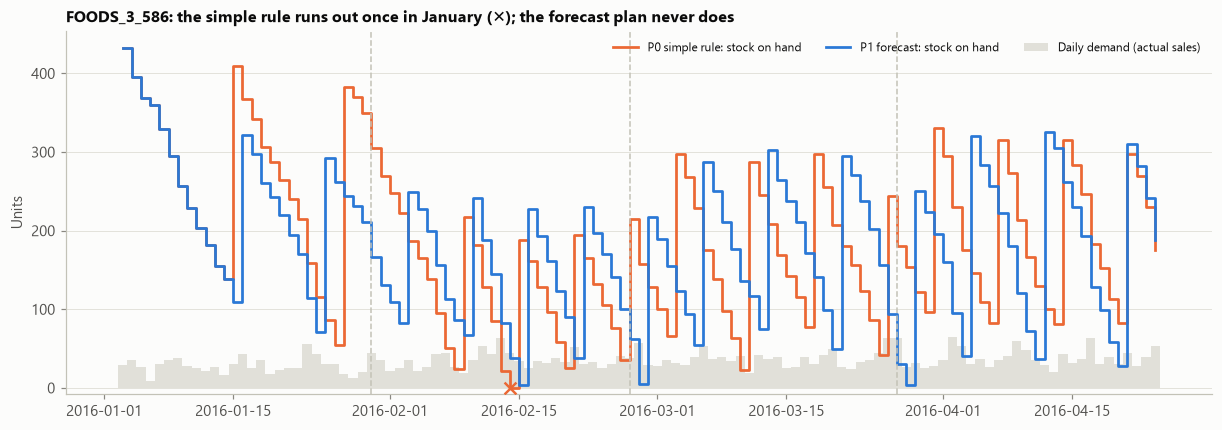

In [3]:
t = trace[trace.item_id == "FOODS_3_586"]
fig, ax = plt.subplots(figsize=(11, 3.8))
d0 = t[t.policy == "P0 baseline"]
ax.bar(d0["date"], d0["demand"], color=P.GRID, width=1, label="Daily demand (actual sales)")
for pol in ["P0 baseline", "P1 forecast"]:
    d = t[t.policy == pol]
    ax.step(d["date"], d["on_hand"], where="post", color=STYLE[pol]["color"], lw=1.8, label=f"{NAMES[pol]}: stock on hand")
    lost = d[d.lost > 0]
    ax.scatter(lost["date"], np.zeros(len(lost)), marker="x", s=60, color=STYLE[pol]["color"], zorder=4)
for o in cfg.forecast.origins[1:]:
    ax.axvline(pd.Timestamp("2011-01-29") + pd.Timedelta(days=o - 1), color=P.AXIS, ls="--", lw=1)
ax.set_ylabel("Units"); ax.set_ylim(bottom=-8)
ax.set_title("FOODS_3_586: the simple rule runs out once in January (✕); the forecast plan never does")
ax.legend(ncols=3, loc="upper right", fontsize=8)
plt.show()

- Both policies follow the same saw-tooth pattern: stock falls, an order arrives, stock jumps.
- The **simple rule** sets its targets from the previous 28 days. When early-January demand differed from late December, it reordered too late once and lost 22 units.
- The **forecast plan** looks ahead over the actual lead-time window, including the weekend peak, so it reorders in time. Dashed lines mark forecast origins, where both policies refresh their inputs.

## 3. The service-vs-stock trade-off

Each policy is run at service targets from 80% to 99%, and each run is plotted as (average stock held, fill rate achieved). **Up and to the left is better**: more service from less stock.

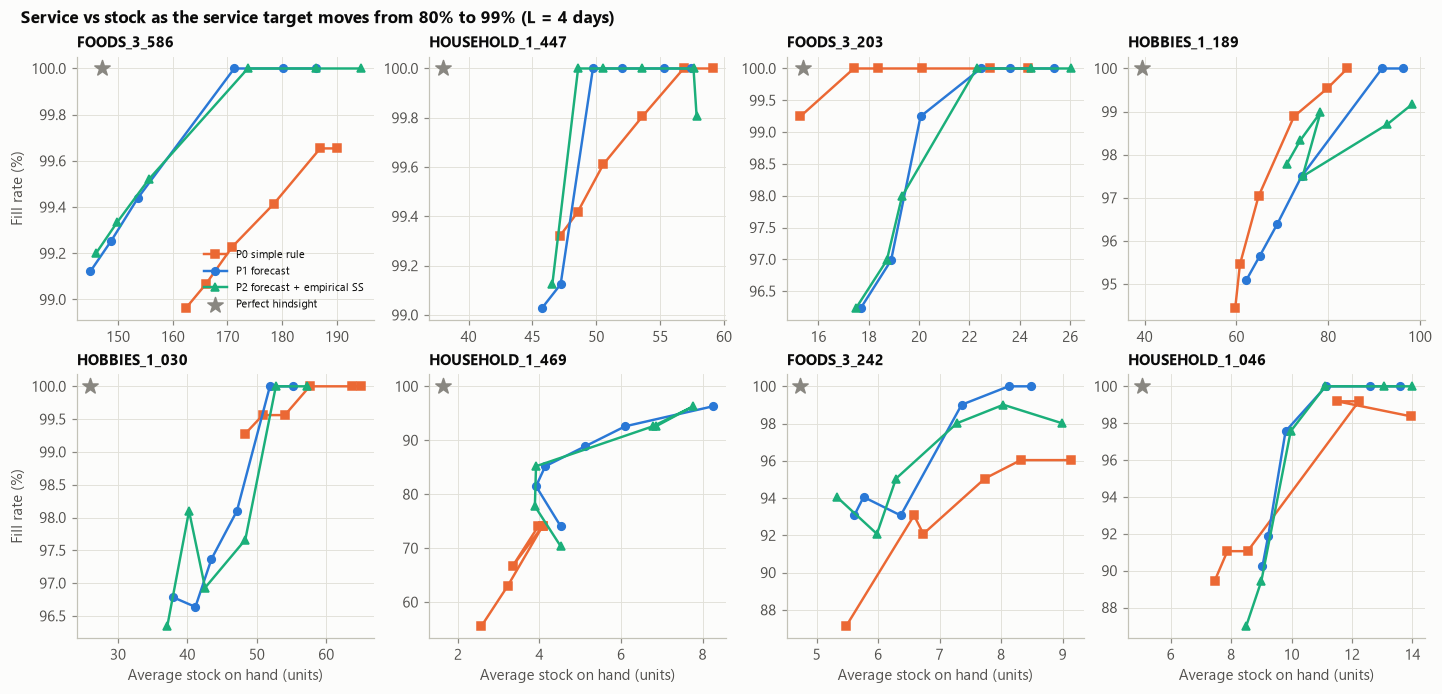

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.2))
for ax, item in zip(axes.flat, ITEMS):
    f = front[front.item_id == item]
    for pol in ["P0 baseline", "P1 forecast", "P2 empirical"]:
        g = f[f.policy == pol].sort_values("target_csl")
        ax.plot(g["avg_on_hand"], g["fill_rate"] * 100, lw=1.6, ms=5, label=NAMES[pol], **STYLE[pol])
    pf = f[f.policy == "Perfect foresight"].iloc[0]
    ax.scatter(pf["avg_on_hand"], 100, color=P.MUTED, marker="*", s=110, zorder=5, label="Perfect hindsight")
    ax.set_title(item, fontsize=9.5)
    ax.grid(axis="x")
for ax in axes[1]:
    ax.set_xlabel("Average stock on hand (units)")
for ax in axes[:, 0]:
    ax.set_ylabel("Fill rate (%)")
axes[0, 0].legend(fontsize=7.5, loc="lower right")
fig.suptitle("Service vs stock as the service target moves from 80% to 99% (L = 4 days)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.show()

**Reading the curves**

- **Forecast policies are more efficient** for FOODS_3_586, HOUSEHOLD_1_447 and FOODS_3_242, and mostly for HOUSEHOLD_1_046 (except at the lowest stock levels). Their curves sit **above or to the left** of the simple rule: the same fill rate from less stock, or more service from the same stock. This is the core result: better demand estimates can make inventory more efficient.
- **HOUSEHOLD_1_469:** the forecast policies reach far higher fill rates (up to 96% vs at most 74%) by holding a little more stock. The simple rule cannot react to this item's changing level.
- **The simple rule is more efficient for FOODS_3_203 and HOBBIES_1_189.** It reaches the same fill rate with clearly less stock. For FOODS_3_203 the forecast policies over-protect: its weekly forecast errors make the buffer larger than this calm series needs. HOBBIES_1_030 is mixed.
- **Fill rate is not always monotonic in the target** (for example HOBBIES_1_189, HOUSEHOLD_1_469). With few stockout events over a 106-day window, single orders swing the outcome. Small differences between curves are within this noise.
- **Perfect hindsight (★)** sits at 100% fill with much less stock than any policy, showing how much headroom remains.
- **P1 vs P2:** the two curves mostly overlap. Replacing the normal-theory buffer with an empirical one changes little here (next section).

## 4. Why the buffers are sometimes too small (or too large)

In [5]:
fc = pd.read_parquet(PROJECT_ROOT / "reports/forecasts/forecasts.parquet")
rq = pd.read_parquet(PROJECT_ROOT / "reports/forecasts/residual_quantiles.parquet")
from scipy.stats import norm
rows = []
for r in choice.itertuples():
    f = fc[(fc.item_id == r.item_id) & (fc.model == r.model) & (fc.origin_d == r.origin_d) & (fc.h <= 28)].dropna(subset=["y_true"])
    e = f["y_true"] - f["yhat"]
    sig = f["sigma_resid"].iloc[0]
    q = lambda lv: rq[(rq.item_id == r.item_id) & (rq.model == r.model) & (rq.origin_d == r.origin_d) & (rq.L == 4) & np.isclose(rq.q, lv)]["value"].iloc[0]
    rows.append({"item_id": r.item_id, "out_of_sample_rmse / in_sample_sigma": np.sqrt((e ** 2).mean()) / sig,
                 "empirical / normal SS (95%)": q(0.95) / (norm.ppf(0.95) * sig * 2),
                 "empirical / normal SS (99%)": q(0.99) / (norm.ppf(0.99) * sig * 2)})
display(pd.DataFrame(rows).groupby("item_id").mean().loc[ITEMS].round(2))

,out_of_sample_rmse / in_sample_sigma,empirical / normal SS (95%),empirical / normal SS (99%)
item_id,,,
FOODS_3_586,0.87,1.08,1.15
HOUSEHOLD_1_447,1.18,1.10,1.08
FOODS_3_203,1.03,1.06,1.15
HOBBIES_1_189,1.18,1.00,1.05
HOBBIES_1_030,1.26,1.00,1.09
HOUSEHOLD_1_469,0.59,1.06,1.06
FOODS_3_242,1.25,1.10,1.04
HOUSEHOLD_1_046,0.95,1.04,1.09


Two different things could make the safety stock wrong. The table separates them.

1. **The distribution assumption (P1 vs P2).** The empirical 4-day buffer is only **0–15% larger** than the normal-theory one at 95% and 99%. Once daily errors are summed over the lead time, the heavy daily tails from notebook 04 largely average out. That is why P2 ≈ P1.
2. **The size of the errors.** Both P1 and P2 size their buffer from **in-sample one-step** errors, but each decision relies on a forecast issued up to 28+ days earlier. The real (out-of-sample) error differs:
   - **Both HOBBIES products, FOODS_3_242 and HOUSEHOLD_1_447:** out-of-sample errors are **18–26% larger**, so buffers are too small. For the spiky HOBBIES items this shows up as missed sales.
   - **FOODS_3_586 and HOUSEHOLD_1_469:** out-of-sample errors are **smaller** (0.87× and 0.59×; HOUSEHOLD_1_469's demand fell during the test period), so stock is over-protected.

**Implication.** The quality of the *error estimate* matters more than its *shape*. The natural next step, not implemented here, is to size buffers from **h-step out-of-sample errors** collected on completed folds, or to re-forecast daily from updated state so the lead-time forecast is always one to L days ahead.

## 5. Sensitivity to lead time and service target

Totals over all 8 products. The cost change is relative to the simple rule; negative means cheaper.

P0 baseline  P1 forecast  P2 empirical  P1 vs P0  P2 vs P0  items where P1 is cheaper
lead_time target_csl                                                                                       
2         0.90              679.8        656.5         673.9    -0.034    -0.009                          5
          0.95              653.4        619.3         633.7    -0.052    -0.030                          5
          0.98              614.7        632.1         612.9     0.028    -0.003                          3
4         0.90              696.4        667.8         687.7    -0.041    -0.012                          6
          0.95              673.9        600.2         594.7    -0.109    -0.118                          7
          0.98              663.7        590.0         587.8    -0.111    -0.114                          6
7         0.90              679.9        655.5         703.4    -0.036     0.035                          6
          0.95              661.0        642.7         666.9    -0.028     0.009                          5
          0.98              661.1        604.1         596.8    -0.086    -0.097                          7

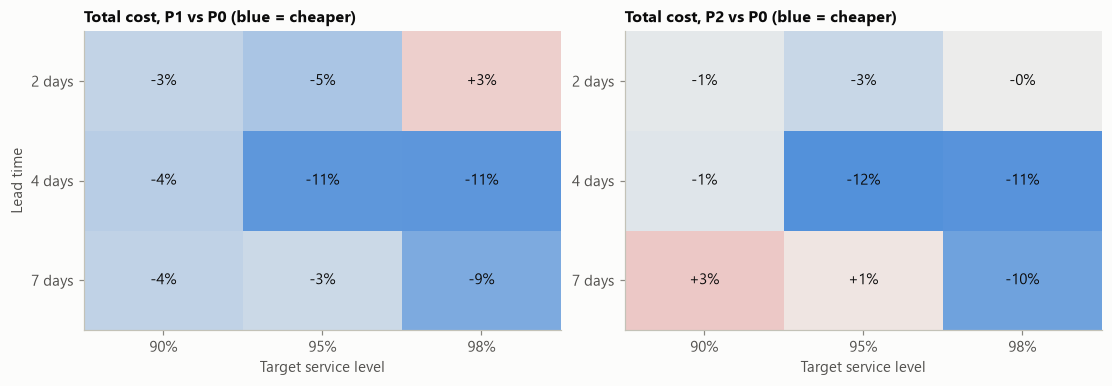

In [6]:
agg = sens.groupby(["lead_time", "target_csl", "policy"]).agg(cost=("total_cost", "sum"), lost=("lost_units", "sum"),
      sold=("sold_units", "sum"), demand=("demand_units", "sum"), stock=("avg_on_hand", "sum")).reset_index()
agg["fill"] = agg["sold"] / agg["demand"]
cost = agg.pivot_table(index=["lead_time", "target_csl"], columns="policy", values="cost")
chg = pd.DataFrame({"P1 vs P0": cost["P1 forecast"] / cost["P0 baseline"] - 1, "P2 vs P0": cost["P2 empirical"] / cost["P0 baseline"] - 1})
cheaper = (sens.pivot_table(index=["lead_time", "target_csl", "item_id"], columns="policy", values="total_cost")
           .eval("`P1 forecast` < `P0 baseline`").groupby(level=[0, 1]).sum().rename("items where P1 is cheaper"))
display(pd.concat([cost[["P0 baseline", "P1 forecast", "P2 empirical"]].round(1), chg.round(3), cheaper], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
for ax, col in zip(axes, ["P1 vs P0", "P2 vs P0"]):
    m = chg[col].unstack("target_csl")
    lim = 0.15
    ax.imshow(m.values, cmap=cmap, norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), aspect="auto")
    ax.set_xticks(range(m.shape[1]), [f"{c:.0%}" for c in m.columns])
    ax.set_yticks(range(m.shape[0]), [f"{int(l)} days" for l in m.index])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m.values[i, j]:+.0%}", ha="center", va="center", fontsize=10, color=P.INK)
    ax.set_title(f"Total cost, {col} (blue = cheaper)")
    ax.set_xlabel("Target service level"); ax.grid(False)
axes[0].set_ylabel("Lead time")
plt.show()

- **P1 is cheaper than the simple rule in 8 of 9 scenarios**, by 3% to 11%. It is 2.8% more expensive at L = 2 with a 98% target. **The default scenario (L = 4, 95%) is the most favourable**, so the headline −11% should always be quoted with this 3–11% range.
- **P2's savings are less consistent**: from −12% to +3.5%, and worse than the simple rule in two scenarios (L = 7 at 90% and 95%).
- In most scenarios the forecast plan **also** loses fewer units. At L = 4 and 98%, it loses 2 units vs 32 for the simple rule.
- Savings do not grow steadily with lead time. That is consistent with Section 4: longer lead times sum more forecast errors, and buffer accuracy is the limiting factor.

## 6. Does forecast accuracy translate into inventory performance?

The forecast-driven policy is re-run with each model **fixed** at every origin, and its total cost is set against that model's forecast accuracy.

,total_cost,lost,stock,mean RMSSE
model,,,,
ets,593.348,47.0,372.349,0.773
croston,597.109,22.0,382.557,0.812
snaive,600.993,60.0,421.679,1.012
arima,625.779,30.0,363.113,0.812
sarima,643.810,50.0,362.792,0.779
ma28,646.008,39.0,406.679,0.821
naive,879.753,176.0,556.368,1.062


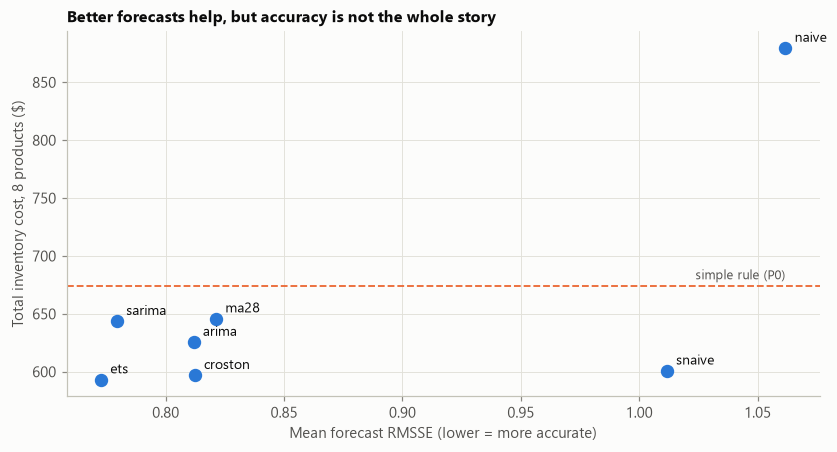

In [7]:
fixed = pm[pm.policy.str.startswith("P1 [")].assign(model=lambda d: d.policy.str[4:-1])
fx = fixed.groupby("model").agg(total_cost=("total_cost", "sum"), lost=("lost_units", "sum"), stock=("avg_on_hand", "sum"))
fx["mean RMSSE"] = summary.groupby("model")["rmsse"].mean()
display(fx.sort_values("total_cost").round(3))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(fx["mean RMSSE"], fx["total_cost"], s=60, color=P.BLUE, zorder=3)
for m, r in fx.iterrows():
    ax.annotate(m, (r["mean RMSSE"], r["total_cost"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
p0 = pm[pm.policy == "P0 baseline"].total_cost.sum()
ax.axhline(p0, color=P.SERIES[1], ls="--", lw=1.2)
ax.text(fx["mean RMSSE"].max(), p0 + 6, "simple rule (P0)", ha="right", color=P.INK_2, fontsize=8.5)
ax.set_xlabel("Mean forecast RMSSE (lower = more accurate)")
ax.set_ylabel("Total inventory cost, 8 products ($)")
ax.set_title("Better forecasts help, but accuracy is not the whole story")
ax.grid(axis="x")
plt.show()

- **Very poor forecasts are expensive.** "Repeat yesterday" (RMSSE 1.06) costs $880 and misses 176 units, worse than the simple rule. Forecasting is not automatically better: the forecast has to be good.
- **Among reasonable models the link is loose.**
  - ETS (most accurate) gives the lowest cost ($593).
  - Seasonal naive (RMSSE 1.01) is close behind ($601).
  - SARIMA, despite near-best accuracy, costs $644.
- **Why the link is loose:** inventory cost depends on the forecast *and* on how well its error estimate sizes the buffer (Section 4). It also depends asymmetrically on under- vs over-forecasting, which RMSSE treats symmetrically.
- **The adaptive policy P1**, which switches models as evidence accumulates, lands at $600: within 1% of the best fixed model, without knowing in advance which one that would be.

## 7. Conclusions and limitations

**Answers to research questions 5 and 6**

- **RQ5: Does a forecast-driven policy beat a simple baseline under the same assumptions?** Mostly yes.
  - It is cheaper in 8 of 9 lead-time/service scenarios (by 3–11%) and on 7 of 8 products in the default scenario, with fewer lost sales.
  - The gains are concentrated in some steady and slow-moving products (FOODS_3_586, HOUSEHOLD_1_447, FOODS_3_242, HOUSEHOLD_1_469). For FOODS_3_203 and the spiky HOBBIES_1_189, the simple rule is more stock-efficient.
- **RQ6: How sensitive are outcomes to lead time, service target and forecast error?**
  - Savings vary with the scenario and peak at L = 4 days with a 95% target.
  - Poor forecasts (naive) are worse than the simple rule.
  - The **accuracy of the error estimate** used for safety stock matters more than the choice between normal and empirical buffers.

**Limitations (also shown in the dashboard)**
- Inventory, lead times and costs are **hypothetical**, and the outcomes depend on them (Section 5).
- Recorded sales are **censored** by Walmart's own stockouts, so true demand on those days is unknown.
- The replay is **short** (106 scored days) and covers 8 products. With few stockout events, individual orders swing the results, especially for spiky items.
- Forecasts are issued once per 28-day fold. Daily re-forecasting with updated state would shorten effective horizons and is the main recommended improvement, together with out-of-sample error estimates for the buffer.
- The (s, S) rule is not cost-optimised. A newsvendor-style service target, set from the shortage/holding cost ratio, could lower costs further.